# Exploring hospital maternal health outcomes

CMS classifies US hospitals as Top, Middle or Bottom Performers based on severe birth complications.
In this notebook, I explore whether other hospital characteristics can help identify Bottom Performers without relying on the complication score itself.

In [51]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 10)
SEED = 42

## 1. Getting to know the data

I start by reading the file as text so that entries such as "Not Available" stay visible before I handle missing values.

In [52]:
raw = pd.read_csv("data/Maternal_Health-Hospital_2.csv", dtype=str)

print("rows and columns:", raw.shape)
print("unique hospitals:", raw["Facility ID"].nunique())
print("rows per hospital:", round(len(raw) / raw["Facility ID"].nunique(), 2))

rows and columns: (17945, 16)
unique hospitals: 4655
rows per hospital: 3.85


## 2. One row per hospital

Each hospital can have up to four measure rows. I bring the scores, delivery counts and performance label together using the facility ID. Text such as "Not Available" becomes a missing value; hospitals without a performance label will not enter the model.

In [53]:
score = raw.pivot_table(index="Facility ID", columns="Measure ID",
                        values="Score", aggfunc="first")
sample = raw.pivot_table(index="Facility ID", columns="Measure ID",
                         values="Sample", aggfunc="first")
category = raw.pivot_table(index="Facility ID", columns="Measure ID",
                           values="Category", aggfunc="first")

hosp = (raw[["Facility ID", "Facility Name", "State"]]
        .drop_duplicates("Facility ID").set_index("Facility ID"))
hosp["cesarean_rate"] = pd.to_numeric(score["PC_02"], errors="coerce")
hosp["deliveries"] = pd.to_numeric(sample["PC_07a"], errors="coerce")
hosp["smm_rate"] = pd.to_numeric(score["PC_07a"], errors="coerce")
hosp["sm7"] = score["SM_7"]
hosp["tier"] = category["PC_07a"].replace(
    ["Not Available", "Not Applicable"], np.nan)

print("Hospital table:", hosp.shape)
print(hosp.isna().sum().to_string())
hosp.head()

Hospital table: (4655, 7)
Facility Name       0
State               0
cesarean_rate    2473
deliveries       2295
smm_rate         2295
sm7                 0
tier             2295


,Facility Name,State,cesarean_rate,deliveries,smm_rate,sm7,tier
Facility ID,,,,,,,
010001,SOUTHEAST HEALTH M...,AL,27.0,1221.0,268.0,Yes,Middle Performer
010005,MARSHALL MEDICAL C...,AL,20.0,1526.0,500.0,Yes,Bottom Performer
010006,NORTH ALABAMA MEDI...,AL,23.0,1150.0,58.0,Yes,Top Performer
010007,MIZELL MEMORIAL HO...,AL,NaN,NaN,NaN,Not Applicable (ou...,NaN
010011,ST. VINCENT'S EAST,AL,NaN,NaN,NaN,Not Applicable (ou...,NaN


## 3. Checking for leakage

The complication rate (`smm_rate`) separates the performance groups without overlapping ranges. Including it would give away the answer, so it stays out of the model, along with the performance label itself.

In [54]:
hosp.groupby("tier")["smm_rate"].agg(["count", "min", "max"])

,count,min,max
tier,,,
Bottom Performer,592,420.0,4531.0
Middle Performer,1177,208.0,419.0
Top Performer,591,31.0,207.0


## 4. Defining the target

I keep hospitals with a reported tier and mark Bottom Performers as 1, all others as 0. About one hospital in four is a Bottom Performer, so predicting 0 for everyone would already give roughly 75% accuracy while finding none of the hospitals of interest.

In [55]:
labelled = hosp[hosp["tier"].notna()].copy()
labelled["is_bottom"] = (labelled["tier"] == "Bottom Performer").astype(int)

print("Hospitals for modelling:", len(labelled))
balance = labelled["is_bottom"].value_counts().sort_index().to_frame("hospitals")
balance["percent"] = 100 * balance["hospitals"] / len(labelled)
balance.rename(index={0: "Not bottom", 1: "Bottom Performer"}).round(1)

Hospitals for modelling: 2360


,hospitals,percent
is_bottom,,
Not bottom,1768,74.9
Bottom Performer,592,25.1


## 5. How does the share vary by state?

I compare states with at least 25 scored hospitals and plot the eight lowest and eight highest shares. This is a descriptive comparison, not a ranking adjusted for patient risk or hospital case mix.

        mean  size
State             
KS     0.077    39
OH     0.077    78
WI     0.097    72
MO     0.107    56
UT     0.122    41
VA     0.149    47
NE     0.158    38
AR     0.167    30
OR     0.174    46
KY     0.186    43
MD     0.188    32
FL     0.194    93
IN     0.200    70
MN     0.200    70
AZ     0.211    38
NC     0.222    72
LA     0.225    40
PA     0.233    73
WA     0.235    51
TN     0.245    53
TX     0.247   186
SC     0.250    36
MI     0.271    70
IL     0.284    81
GA     0.303    66
MS     0.314    35
IA     0.320    50
OK     0.326    43
CA     0.352   182
NJ     0.386    44
CO     0.408    49
AL     0.421    38
MA     0.459    37
NY     0.510   100


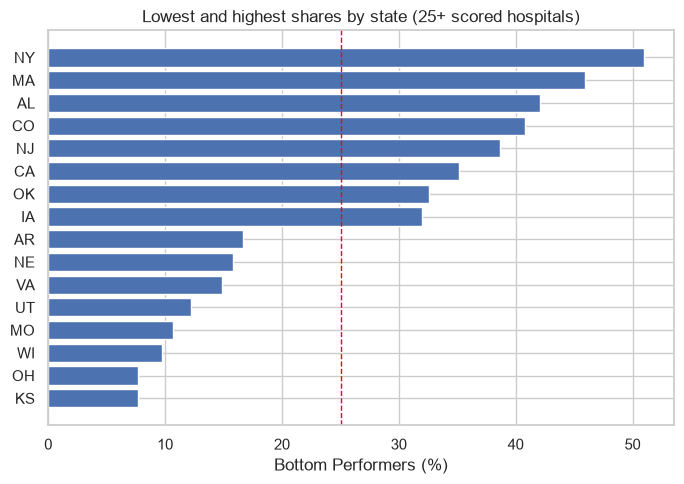

In [56]:
by_state = (labelled.groupby("State")["is_bottom"].agg(["mean", "size"])
            .query("size >= 25").sort_values("mean"))
print(by_state.round(3).to_string())

ends = pd.concat([by_state.head(8), by_state.tail(8)])
fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(ends.index, 100 * ends["mean"])
ax.axvline(100 * labelled["is_bottom"].mean(), color="red", ls="--", lw=1)
ax.set_xlabel("Bottom Performers (%)")
ax.set_title("Lowest and highest shares by state (25+ scored hospitals)")
fig.tight_layout()
plt.show()

## 6. Cesarean-rate quintiles

I divide hospitals into five similarly sized groups by cesarean rate, then compare their shares of Bottom Performers. Missing cesarean rates do not enter these groups. An association here does not show that cesareans cause complications.

                 mean  size
cesarean_rate              
(-0.001, 20.0]  0.215   475
(20.0, 24.0]    0.218   510
(24.0, 27.0]    0.237   434
(27.0, 30.0]    0.307   365
(30.0, 100.0]   0.325   397


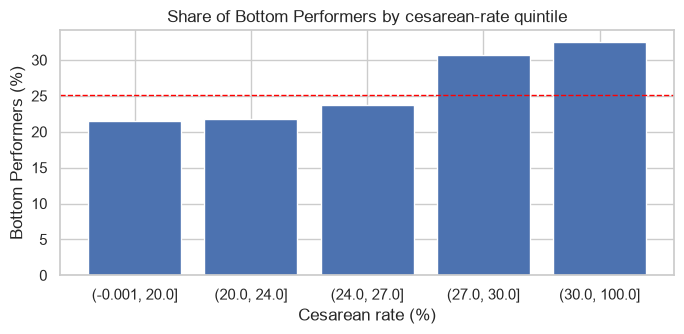

In [57]:
quintile = pd.qcut(labelled["cesarean_rate"], 5)
ces = labelled.groupby(quintile, observed=True)["is_bottom"].agg(["mean", "size"])
print(ces.round(3).to_string())

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar([str(interval) for interval in ces.index], 100 * ces["mean"])
ax.axhline(100 * labelled["is_bottom"].mean(), color="red", ls="--", lw=1)
ax.set_xlabel("Cesarean rate (%)")
ax.set_ylabel("Bottom Performers (%)")
ax.set_title("Share of Bottom Performers by cesarean-rate quintile")
fig.tight_layout()
plt.show()

## 7. Does safety attestation help?

I compare hospitals reporting "Yes" for SM_7 with all other responses, using the same grouping as before. Their Bottom Performer shares are nearly identical. This simple comparison does not establish that safety practices have no effect, and the other-response group should not be read as a confirmed "No".

In [58]:
labelled["sm7_adopted"] = (labelled["sm7"] == "Yes").astype(int)
sm7_summary = labelled.groupby("sm7_adopted")["is_bottom"].agg(["mean", "size"])
sm7_summary.rename(index={0: "Other response", 1: "Yes"}).round(3)

,mean,size
sm7_adopted,,
Other response,0.247,186
Yes,0.251,2174


## 8. Features, split and preprocessing

The model keeps four inputs: cesarean rate, log delivery volume, a rough academic-name flag and state group. The log reduces the spread in delivery volume. The name flag is only a proxy, not verified academic status.

I keep the original split (25% test, seed 42, stratified) and preprocessing so the results remain comparable. Missing numeric values are filled with the training median, which is less sensitive to extremes than the mean. Numeric features are standardized and state groups are one-hot encoded.

To reproduce the earlier analysis, states with fewer than 25 labelled hospitals are grouped as OTHER before the split. This uses full-sample category frequencies; in a stricter validation, that grouping and exploratory feature choices should be learned from training data only.

In [59]:
model_df = labelled.copy()
model_df["log_deliveries"] = np.log10(model_df["deliveries"])
model_df["is_academic"] = (model_df["Facility Name"].str.upper()
    .str.contains(r"UNIV|COLLEGE|SCHOOL OF MED", regex=True, na=False).astype(int))
state_counts = model_df["State"].value_counts()
big_states = state_counts[state_counts >= 25].index
model_df["state_grp"] = np.where(
    model_df["State"].isin(big_states), model_df["State"], "OTHER")

NUMERIC = ["cesarean_rate", "log_deliveries"]
FEATURES = NUMERIC + ["is_academic", "state_grp"]
X = model_df[FEATURES]
y = model_df["is_bottom"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=SEED, stratify=y)

prep = ColumnTransformer([
    ("num", Pipeline([("impute", SimpleImputer(strategy="median")),
                      ("scale", StandardScaler())]), NUMERIC),
    ("bin", "passthrough", ["is_academic"]),
    ("cat", OneHotEncoder(handle_unknown="ignore", drop="first",
                           sparse_output=False), ["state_grp"]),
])
print("Train:", X_train.shape, "Test:", X_test.shape)
print("Bottom Performer share: train %.3f, test %.3f"
      % (y_train.mean(), y_test.mean()))

Train: (1770, 4) Test: (590, 4)
Bottom Performer share: train 0.251, test 0.251


## 9. Dummy versus logistic regression

I compare a majority-class baseline with logistic regression, using balanced class weights so the smaller class gets more weight during fitting. Each pipeline learns its preprocessing from the training set only.

Both models use their default decision rule. Accuracy alone favors the dummy, so I also report precision, recall, F1 and ROC AUC, plus the logistic regression confusion matrix. These are held-out results for this split, not proof that the model will generalize to other periods or settings.

                     accuracy  precision  recall     f1  roc_auc
model                                                           
Dummy                   0.749      0.000   0.000  0.000    0.500
Logistic regression     0.603      0.319   0.514  0.394    0.623


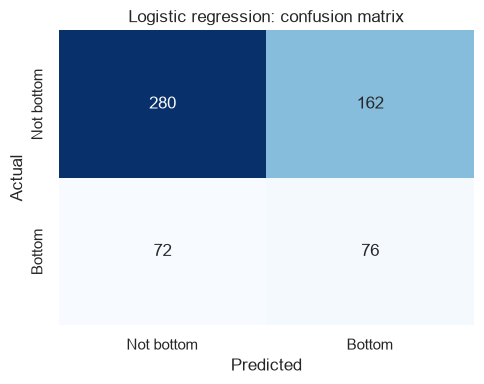

In [60]:
models = {
    "Dummy": DummyClassifier(strategy="most_frequent"),
    "Logistic regression": LogisticRegression(max_iter=3000, class_weight="balanced"),
}

results = []
for name, estimator in models.items():
    fitted = Pipeline([("prep", prep), ("clf", estimator)]).fit(X_train, y_train)
    prediction = fitted.predict(X_test)
    probability = fitted.predict_proba(X_test)[:, 1]
    results.append({
        "model": name,
        "accuracy": accuracy_score(y_test, prediction),
        "precision": precision_score(y_test, prediction, zero_division=0),
        "recall": recall_score(y_test, prediction, zero_division=0),
        "f1": f1_score(y_test, prediction, zero_division=0),
        "roc_auc": roc_auc_score(y_test, probability),
    })

metrics = pd.DataFrame(results).set_index("model")
print(metrics.round(3).to_string())
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(confusion_matrix(y_test, prediction), annot=True, fmt="d",
            cmap="Blues", cbar=False, ax=ax,
            xticklabels=["Not bottom", "Bottom"], yticklabels=["Not bottom", "Bottom"])
ax.set_xlabel("Predicted")
ax.set_ylabel("Actual")
ax.set_title("Logistic regression: confusion matrix")
fig.tight_layout()
plt.show()

## Conclusions and limitations

About one in four scored hospitals is a Bottom Performer. The share varies widely by state, from 8% in Kansas to 51% in New York, and rises from 21.5% to 32.5% across cesarean-rate quintiles. SM_7 shows little difference between groups.

The model finds about half of the Bottom Performers, but only one in three flags is correct (AUC 0.623). The dummy gets higher accuracy by predicting that no hospital is a Bottom Performer, so accuracy alone is misleading here.

I would not use this model to judge a hospital. Missing data, differences in patient mix and the rough academic-name flag leave a lot unexplained. These patterns do not prove cause and effect. I also used the full sample to explore features and group states, then evaluated on just one split. The scores are not calibrated risks, and the model needs testing on new data.